# Code for IG Reel project

In [1]:
import numpy as np  
import pandas as pd 
import warnings
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)

# Loading Data

In [2]:
df = pd.read_csv("../data/instagram data.csv")
print(df.head())
df.isna().sum()

                                reel_id                            creator_id  \
0  c437715e-d1e4-4f40-8548-8718243c6516  70c2ca5a-9d3a-4ba0-9aed-62cdbbc1663f   
1  9097bb11-0e03-4360-a239-6613ed2025df  b6bb4240-6341-47ce-bdd4-86fcba18d9ad   
2  a8e09994-3314-400b-9f3a-683b494f1070  7902b14d-cb95-4673-8ef1-482ff5151801   
3  afafb1c3-90c4-4918-8910-3a2338a812c5  3878d999-6087-4a40-a59e-45abe8978736   
4  dcb1e68c-79ba-4808-bf74-d102fa68a526  4077faf8-bc0c-42df-b060-f90d074e8e01   

   creator_followers  posting_time  reel_length_sec  hook_strength_score  \
0            4208388             3               31             0.451657   
1            4096880             4               38             0.988437   
2            2624351             0               13             0.019949   
3             437778            23               15             0.564485   
4            4388903             3               30             0.556782   

   caption_length  hashtags_count  trending_audio  audio

reel_id                     0
creator_id                  0
creator_followers           0
posting_time                0
reel_length_sec             0
hook_strength_score         0
caption_length              0
hashtags_count              0
trending_audio              0
audio_popularity_score      0
video_quality_score         0
editing_quality_score       0
avg_watch_time_sec          0
retention_rate              0
completion_rate             0
rewatch_rate                0
likes                       0
comments                    0
shares                      0
saves                       0
engagement_rate             0
impressions                 0
reach                       0
non_follower_reach_ratio    0
explore_page_boost          0
virality_score              0
dtype: int64

In [3]:
cols = ["virality_score", "hook_strength_score", "hashtags_count", "impressions", "creator_followers", "trending_audio", "retention_rate"]
df = df[cols]
print(df.head())

   virality_score  hook_strength_score  hashtags_count  impressions  \
0       82.843160             0.451657              20     75968410   
1       60.256519             0.988437               2     90722120   
2        0.483295             0.019949               6     75215994   
3       21.686033             0.564485               1     32759775   
4       46.046599             0.556782              27     12315042   

   creator_followers  trending_audio  retention_rate  
0            4208388            True        0.144017  
1            4096880           False        0.887992  
2            2624351            True        0.839839  
3             437778           False        0.116623  
4            4388903           False        0.925694  


In [4]:
df.shape
df.describe()

,virality_score,hook_strength_score,hashtags_count,impressions,creator_followers,retention_rate
count,100000.000000,100000.000000,100000.000000,1.000000e+05,1.000000e+05,100000.000000
mean,50.120510,0.498998,15.068680,4.993031e+07,2.501074e+06,0.500986
std,28.948261,0.288684,8.953352,2.882719e+07,1.446318e+06,0.288334
min,0.000075,0.000009,0.000000,2.737000e+03,5.210000e+02,0.000017
25%,25.101121,0.248077,7.000000,2.492035e+07,1.241770e+06,0.251674
50%,50.089255,0.499020,15.000000,4.991705e+07,2.500456e+06,0.501637
75%,75.280233,0.749162,23.000000,7.492529e+07,3.754132e+06,0.749623
max,99.999949,0.999997,30.000000,9.999951e+07,4.999946e+06,0.999997


In [5]:
df["bin_viral"] = (df["virality_score"] >= df["virality_score"].quantile(0.995)).astype(int) # top 0.5% virality score

df["strong_hook"] = (df["hook_strength_score"] >= df["hook_strength_score"].quantile(0.5)).astype(int) # more than 0.5 hook strength score
df["many_hashtags"] = (df["hashtags_count"] >= df["hashtags_count"].quantile(0.5)).astype(int) # equal to or more than 15 hashtags
df["many_impressions"] = (df["impressions"] >= df["impressions"].quantile(0.5)).astype(int) # more than 50 million impressions
df["many_followers"] = (df["creator_followers"] >= df["creator_followers"].quantile(0.5)).astype(int) # more than 2.5 million followers
df["trending_audio"] = df["trending_audio"].astype(int) # trending audio (true = 1, false = 0)
df["high_retention"] = (df["retention_rate"] >= df["retention_rate"].quantile(0.5)).astype(int) # more than 50% retention rate
df.head()


,virality_score,hook_strength_score,hashtags_count,impressions,creator_followers,trending_audio,retention_rate,bin_viral,strong_hook,many_hashtags,many_impressions,many_followers,high_retention
0,82.843160,0.451657,20,75968410,4208388,1,0.144017,0,0,1,1,1,0
1,60.256519,0.988437,2,90722120,4096880,0,0.887992,0,1,0,1,1,1
2,0.483295,0.019949,6,75215994,2624351,1,0.839839,0,0,0,1,1,1
3,21.686033,0.564485,1,32759775,437778,0,0.116623,0,1,0,0,0,0
4,46.046599,0.556782,27,12315042,4388903,0,0.925694,0,1,1,0,1,1


In [6]:
bin_df = df[["bin_viral", "strong_hook", "many_hashtags", "many_impressions", "many_followers", "trending_audio", "high_retention"]]
bin_df.head()

,bin_viral,strong_hook,many_hashtags,many_impressions,many_followers,trending_audio,high_retention
0,0,0,1,1,1,1,0
1,0,1,0,1,1,0,1
2,0,0,0,1,1,1,1
3,0,1,0,0,0,0,0
4,0,1,1,0,1,0,1


# EDA

Base rate P(viral) = 0.00500  (500 viral of 100000)

                  n(f=0)  n(f=1)  viral(f=0)  viral(f=1)  P(viral|f=0)  \
feature                                                                  
strong_hook        50000   50000         246         254       0.00492   
many_hashtags      48109   51891         253         247       0.00526   
many_impressions   50000   50000         255         245       0.00510   
many_followers     50000   50000         250         250       0.00500   
trending_audio     50083   49917         253         247       0.00505   
high_retention     50000   50000         258         242       0.00516   

                  P(viral|f=1)     diff   ci_low  ci_high  
feature                                                    
strong_hook            0.00508  0.00016 -0.00071  0.00103  
many_hashtags          0.00476 -0.00050 -0.00138  0.00038  
many_impressions       0.00490 -0.00020 -0.00107  0.00067  
many_followers         0.00500  0.00000 -0.00087  0.00

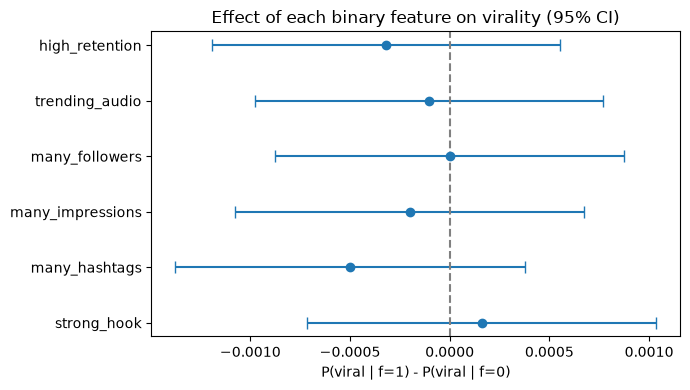

In [7]:
Y = "bin_viral"
feats = [c for c in bin_df.columns if c != Y]

rows = []
for f in feats:
    ct = pd.crosstab(bin_df[f], bin_df[Y])          
    n0, n1 = ct.loc[0].sum(), ct.loc[1].sum()
    v0, v1 = ct.loc[0, 1], ct.loc[1, 1]
    p0, p1 = v0 / n0, v1 / n1

    se = np.sqrt(p0 * (1 - p0) / n0 + p1 * (1 - p1) / n1)
    diff = p1 - p0
    rows.append({
        "feature": f,
        "n(f=0)": n0, "n(f=1)": n1,
        "viral(f=0)": v0, "viral(f=1)": v1,
        "P(viral|f=0)": p0, "P(viral|f=1)": p1,
        "diff": diff,
        "ci_low": diff - 1.96 * se, "ci_high": diff + 1.96 * se,
    })

eda = pd.DataFrame(rows).set_index("feature")
print(f"Base rate P(viral) = {bin_df[Y].mean():.5f}  ({bin_df[Y].sum()} viral of {len(bin_df)})\n")
print(eda.round(5))


fig, ax = plt.subplots(figsize=(7, 4))
y = np.arange(len(eda))
ax.errorbar(eda["diff"], y,
            xerr=[eda["diff"] - eda["ci_low"], eda["ci_high"] - eda["diff"]],
            fmt="o", capsize=4)
ax.axvline(0, color="gray", linestyle="--")
ax.set_yticks(y)
ax.set_yticklabels(eda.index)
ax.set_xlabel("P(viral | f=1) - P(viral | f=0)")
ax.set_title("Effect of each binary feature on virality (95% CI)")
plt.tight_layout()
plt.show()

# Modeling and Inference

In [8]:
from pgmpy.models import DiscreteBayesianNetwork  
from pgmpy.estimators import MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination, ApproxInference
from pgmpy.sampling import BayesianModelSampling
from pgmpy.factors.discrete import State

Y = "bin_viral"
H, T, F, A, R, I = ("strong_hook", "many_hashtags", "many_followers",
                    "trending_audio", "high_retention", "many_impressions")

structures = {
    "model1_baseline": [(x, Y) for x in (H, T, F, A, R, I)],
    "model2_dependency": [(x, Y) for x in (H, T, F, A, R, I)]
                         + [(T, I), (F, I), (A, I), (H, R)],
    "model3_funnel": [(T, I), (F, I), (A, I), (H, R), (I, Y), (R, Y)],
}

def fit_mle(edges, data):
    model = DiscreteBayesianNetwork(edges)
    nodes = list(model.nodes())
    est = MaximumLikelihoodEstimator(model, data[nodes])
    cpds = est.get_parameters()          
    model.add_cpds(*cpds)
    assert model.check_model()
    return model

models = {name: fit_mle(edges, bin_df) for name, edges in structures.items()}


def lw_estimate(model, evidence, n, seed=0):
    sampler = BayesianModelSampling(model)
    ev = [State(k, v) for k, v in evidence.items()]
    s = sampler.likelihood_weighted_sample(evidence=ev, size=n, seed=seed)
    return (s["_weight"] * (s[Y] == 1)).sum() / s["_weight"].sum()

def rejection_estimate(model, evidence, n, seed=0):
    sampler = BayesianModelSampling(model)
    ev = [State(k, v) for k, v in evidence.items()]
    r = sampler.rejection_sample(evidence=ev, size=n, seed=seed)
    return (r[Y] == 1).mean(), len(r)

def exact_p(model, evidence):
    q = VariableElimination(model).query([Y], evidence=evidence, show_progress=False)
    return q.get_value(**{Y: 1})


baseline = models["model1_baseline"]
evidence = {H: 1, F: 1, R: 1}   

p_exact = exact_p(baseline, evidence)
p_lw = lw_estimate(baseline, evidence, 100_000)
p_rej, kept = rejection_estimate(baseline, evidence, 100_000)

print(f"Exact:              {p_exact:.5f}")
print(f"Likelihood weight:  {p_lw:.5f}")
print(f"Rejection sampling: {p_rej:.5f} (kept {kept})")

approx = ApproxInference(baseline).query(
    variables=[Y], evidence=evidence, n_samples=100_000, show_progress=False
)
print("pgmpy ApproxInference:\n", approx)

for name, m in models.items():
    ev = {k: v for k, v in evidence.items() if k in m.nodes()}
    print(f"{name:20s} exact={exact_p(m, ev):.5f}  "
          f"LW={lw_estimate(m, ev, 100_000):.5f}")

  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/100000 [00:00<?, ?it/s]

Exact:              0.00531
Likelihood weight:  0.00540
Rejection sampling: 0.00527 (kept 100000)
pgmpy ApproxInference:
 +--------------+------------------+
| bin_viral    |   phi(bin_viral) |
+==============+==================+
| bin_viral(0) |           0.9946 |
+--------------+------------------+
| bin_viral(1) |           0.0054 |
+--------------+------------------+


  0%|          | 0/7 [00:00<?, ?it/s]

model1_baseline      exact=0.00531  LW=0.00540


  0%|          | 0/7 [00:00<?, ?it/s]

model2_dependency    exact=0.00531  LW=0.00538


  0%|          | 0/7 [00:00<?, ?it/s]

model3_funnel        exact=0.00484  LW=0.00496


  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/7 [00:00<?, ?it/s]

... (27 outputs left out)

  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/7 [00:00<?, ?it/s]

value                                      0         1
model             feature                             
model1_baseline   high_retention    0.005020  0.004610
                  many_followers    0.004870  0.004820
                  many_hashtags     0.005090  0.004620
                  many_impressions  0.004960  0.004740
                  strong_hook       0.004740  0.004950
                  trending_audio    0.004960  0.004810
model2_dependency high_retention    0.005010  0.004620
                  many_followers    0.004870  0.004830
                  many_hashtags     0.005120  0.004620
                  many_impressions  0.004965  0.004747
                  strong_hook       0.004740  0.004940
                  trending_audio    0.004950  0.004810
model3_funnel     high_retention    0.004970  0.004580
                  many_followers    0.004770  0.004770
                  many_hashtags     0.004780  0.004780
                  many_impressions  0.004898  0.004647
          

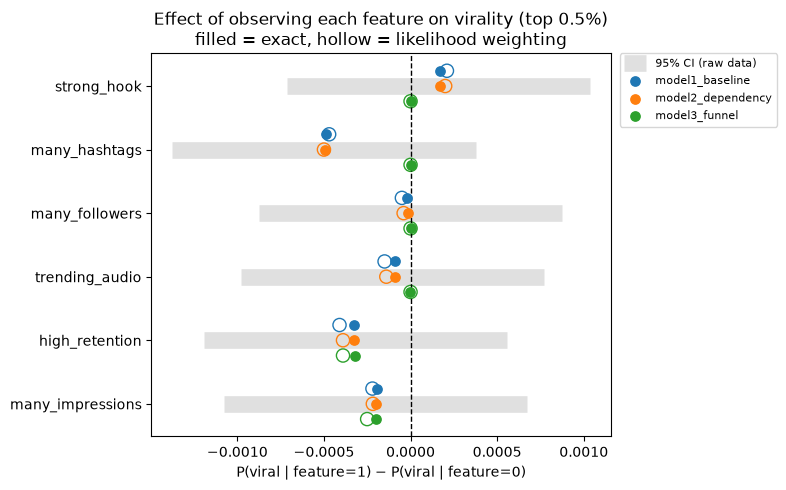

In [9]:
features = [H, T, F, A, R, I]
rows = []
for name, m in models.items():
    for f in features:
        if f not in m.nodes():
            continue
        for v in (0, 1):
            ev = {f: v}
            rows.append({
                "model": name, "feature": f, "value": v,
                "exact": exact_p(m, ev),
                "LW": lw_estimate(m, ev, 100_000),
            })
results = pd.DataFrame(rows)
print(results.pivot_table(index=["model", "feature"], columns="value", values="LW"))

w = results.pivot_table(index=["model", "feature"], columns="value", values=["exact", "LW"])
eff = pd.DataFrame({
    "exact": w[("exact", 1)] - w[("exact", 0)],
    "LW":    w[("LW", 1)]    - w[("LW", 0)],
}).reset_index()

ci = {}
for f in features:
    g = bin_df.groupby(f)[Y].agg(["mean", "count"])
    p0, p1, n0, n1 = g.loc[0, "mean"], g.loc[1, "mean"], g.loc[0, "count"], g.loc[1, "count"]
    d, se = p1 - p0, np.sqrt(p0*(1-p0)/n0 + p1*(1-p1)/n1)
    ci[f] = (d - 1.96*se, d + 1.96*se)

model_names = list(models.keys())
colors = dict(zip(model_names, ["tab:blue", "tab:orange", "tab:green", "tab:red"]))
offsets = dict(zip(model_names, np.linspace(-0.24, 0.24, len(model_names))))
ypos = {f: i for i, f in enumerate(features)}

fig, ax = plt.subplots(figsize=(8, 5))

for f in features:
    ax.hlines(ypos[f], *ci[f], color="lightgray", lw=12, alpha=0.7, zorder=1,
              label="95% CI (raw data)" if f == features[0] else None)

for m_name in model_names:
    d = eff[eff.model == m_name]
    y = [ypos[f] + offsets[m_name] for f in d.feature]
    ax.scatter(d["exact"], y, color=colors[m_name], s=45, zorder=3, label=m_name)
    ax.scatter(d["LW"], y, facecolors="none", edgecolors=colors[m_name], s=90, zorder=2)

ax.axvline(0, color="black", ls="--", lw=1)
ax.set_yticks(list(ypos.values()))
ax.set_yticklabels(list(ypos.keys()))
ax.invert_yaxis()
ax.set_xlabel("P(viral | feature=1) − P(viral | feature=0)")
ax.set_title("Effect of observing each feature on virality (top 0.5%)\nfilled = exact, hollow = likelihood weighting")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.tight_layout()
plt.show()

In [10]:
model4 = fit_mle([(H, Y), (T, Y), (A, Y)], bin_df)

evidence4 = {H: 1, A: 1}

p_exact = exact_p(model4, evidence4)
p_lw = lw_estimate(model4, evidence4, 100_000)
p_rej, _ = rejection_estimate(model4, evidence4, 100_000)
approx = ApproxInference(model4).query(
    variables=[Y], evidence=evidence4, n_samples=100_000, show_progress=False
)

print(f"Model 4 evidence: {evidence4}")
print(f"Exact:              {p_exact:.5f}")
print(f"Likelihood weight:  {p_lw:.5f}")
print(f"Rejection sampling: {p_rej:.5f}")
print("pgmpy ApproxInference:\n", approx)


for name, ev in {"all_on": {H: 1, T: 1, A: 1}, "all_off": {H: 0, T: 0, A: 0}}.items():
    print(f"{name}: exact={exact_p(model4, ev):.5f}  LW={lw_estimate(model4, ev, 100_000):.5f}")

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/100000 [00:00<?, ?it/s]

Model 4 evidence: {'strong_hook': 1, 'trending_audio': 1}
Exact:              0.00510
Likelihood weight:  0.00528
Rejection sampling: 0.00531
pgmpy ApproxInference:
 +--------------+------------------+
| bin_viral    |   phi(bin_viral) |
+==============+==================+
| bin_viral(0) |           0.9952 |
+--------------+------------------+
| bin_viral(1) |           0.0048 |
+--------------+------------------+


  0%|          | 0/4 [00:00<?, ?it/s]

all_on: exact=0.00442  LW=0.00450


  0%|          | 0/4 [00:00<?, ?it/s]

all_off: exact=0.00387  LW=0.00393


  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/100000 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/100000 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/100000 [00:00<?, ?it/s]

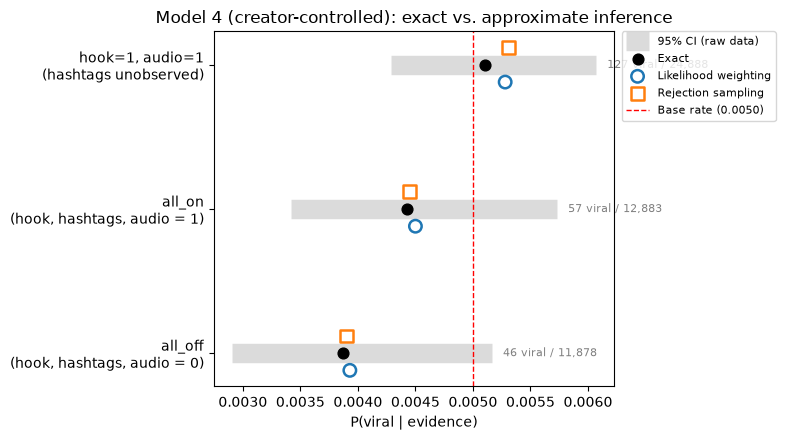

In [11]:
scenarios = {
    "hook=1, audio=1\n(hashtags unobserved)": {H: 1, A: 1},
    "all_on\n(hook, hashtags, audio = 1)":     {H: 1, T: 1, A: 1},
    "all_off\n(hook, hashtags, audio = 0)":    {H: 0, T: 0, A: 0},
}

def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

rows = []
for label, ev in scenarios.items():
    mask = np.logical_and.reduce([bin_df[k] == v for k, v in ev.items()])
    k, n = bin_df.loc[mask, Y].sum(), mask.sum()
    lo, hi = wilson(k, n)
    rows.append({
        "label": label,
        "exact": exact_p(model4, ev),
        "LW": lw_estimate(model4, ev, 100_000),
        "rej": rejection_estimate(model4, ev, 100_000)[0],
        "lo": lo, "hi": hi, "n_viral": k, "n": n,
    })

base = bin_df[Y].mean()
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(rows))

for i, r in enumerate(rows):
    ax.hlines(i, r["lo"], r["hi"], color="lightgray", lw=14, alpha=0.8, zorder=1,
              label="95% CI (raw data)" if i == 0 else None)
    ax.scatter(r["exact"], i, color="black", s=60, zorder=4, label="Exact" if i == 0 else None)
    ax.scatter(r["LW"], i + 0.12, facecolors="none", edgecolors="tab:blue", s=80, lw=1.8,
               zorder=3, label="Likelihood weighting" if i == 0 else None)
    ax.scatter(r["rej"], i - 0.12, facecolors="none", edgecolors="tab:orange", s=80, lw=1.8,
               marker="s", zorder=3, label="Rejection sampling" if i == 0 else None)
    ax.text(r["hi"] + 0.0001, i, f"{r['n_viral']} viral / {r['n']:,}", va="center", fontsize=8, color="gray")

ax.axvline(base, color="red", ls="--", lw=1, label=f"Base rate ({base:.4f})")
ax.set_yticks(y)
ax.set_yticklabels([r["label"] for r in rows])
ax.invert_yaxis()
ax.set_xlabel("P(viral | evidence)")
ax.set_title("Model 4 (creator-controlled): exact vs. approximate inference")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.tight_layout()
plt.show()